In [1]:
import numpy as np
import pandas as pd
import math
import time
import matplotlib.pyplot as plt
from IPython.display import display, Math

eps = 1e-6
max_iterations = 100

sig = lambda value: np.format_float_positional(value, precision=3, unique=False, fractional=False, trim='k').rstrip('.')

# Численные методы
Реализуем методы, которые требуются в варианте 9: метод секущих (МС) и метод Ньютона (МН).

## Метод секущих
$$
x_{n+1} = x_n - \frac{x_n - x_{n-1}}{f(x_n) - f(x_{n-1})} f(x_n)
$$
За разгонные точки $x_0, x_1$ берём границы отрезка. Итерации прекращаются при $|x_{n+1} - x_n| < \varepsilon$.
На каждой итерации вычисляется только одно новое значение функции, предыдущее запоминается.

In [2]:
def secant(f, x0, x1, eps=eps, max_iterations=max_iterations):
    f0, f1 = f(x0), f(x1)
    iterations = 0
    condition = True

    while condition and iterations < max_iterations:
        iterations += 1
        x_i = x1 - (x1 - x0) / (f1 - f0) * f1
        condition = abs(x_i - x1) >= eps
        x0, f0 = x1, f1
        x1, f1 = x_i, f(x_i)

    return x1, iterations

## Метод Ньютона
$$
x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}
$$
Начальное приближение $x_0$ выбираем на границе отрезка так, чтобы $f(x_0) f''(x_0) > 0$.

In [3]:
def newton(f, derivative, x0, eps=eps, max_iterations=max_iterations):
    x_i = x0
    iterations = 0
    condition = True

    while condition and iterations < max_iterations:
        iterations += 1
        delta = f(x_i) / derivative(x_i)
        x_i -= delta
        condition = abs(delta) >= eps

    return x_i, iterations


def newton_start(f, second_derivative, a, b):
    return a if f(a) * second_derivative(a) > 0 else b

## Проверка условий
На отрезке $[a, b]$ проверяем следствие теоремы Больцано-Коши:
- $f(a) f(b) < 0$;
- $f'(x)$ и $f''(x)$ не меняют знак на $[a, b]$.

Для метода Ньютона дополнительно проверяем условие сходимости на всём отрезке:
$$
|f(x) f''(x)| < (f'(x))^2
$$

In [4]:
def is_constant_sign(values):
    return bool(np.all(values > 0) or np.all(values < 0))


def check_root_conditions(f, derivative, second_derivative, a, b, points=10_000):
    x = np.linspace(a, b, points)
    return {
        "f(a) f(b) < 0": bool(f(a) * f(b) < 0),
        "f' не меняет знак": is_constant_sign(derivative(x)),
        "f'' не меняет знак": is_constant_sign(second_derivative(x)),
    }


def check_newton_condition(f, derivative, second_derivative, a, b, points=10_000):
    x = np.linspace(a, b, points)
    return bool(np.all(np.abs(f(x) * second_derivative(x)) < derivative(x) ** 2))

Для сравнения скорости методов используем **реальное время** (`time.perf_counter_ns`).
Один запуск длится единицы микросекунд, поэтому усредняем время по многим повторениям.

In [5]:
def measure_time(method, *args, repeats=10_000):
    start = time.perf_counter_ns()
    for _ in range(repeats):
        method(*args)
    return (time.perf_counter_ns() - start) / repeats / 1000

# Задание 1
На клин набегает поток совершенного невязкого газа с $\kappa = 1.4$. Определим угол наклона КСУ $\theta_c$ методом секущих и параметры за скачком.

Исходные данные (вариант 9):

In [6]:
p1 = 75000
T1 = 288
M1 = 3
beta = math.radians(10)

kappa = 1.4
R = 287

display(pd.DataFrame(
    {
        "Параметр": ["p1", "T1", "M1", "β", "κ", "R"],
        "Значение": [p1, T1, M1, 10, kappa, R],
        "Размерность": ["Па", "К", "—", "°", "—", "Дж/(кг·К)"],
    }
))

,Параметр,Значение,Размерность
0,p1,75000.0,Па
1,T1,288.0,К
2,M1,3.0,—
3,β,10.0,°
4,κ,1.4,—
5,R,287.0,Дж/(кг·К)


Параметры набегающего потока:
$$
\rho_1 = \frac{p_1}{R T_1}, \quad a_1 = \sqrt{\kappa R T_1}, \quad v_1 = M_1 a_1
$$

In [7]:
rho1 = p1 / (R * T1)
a1 = math.sqrt(kappa * R * T1)
v1 = M1 * a1

display(Math(fr"\rho_1 = {sig(rho1)}\ кг/м^3, \quad a_1 = {sig(a1)}\ м/с, \quad v_1 = {sig(v1)}\ м/с"))

<IPython.core.display.Math object>

Уравнение для угла наклона скачка (4):
$$
f(\theta_c) = \sin^2\theta_c - \frac{\kappa + 1}{2} \frac{\sin\theta_c \sin\beta}{\cos(\theta_c - \beta)} - \frac{1}{M_1^2} = 0
$$

In [8]:
k = (kappa + 1) / 2

shock_equation = lambda t: np.sin(t) ** 2 - k * np.sin(t) * np.sin(beta) / np.cos(t - beta) - 1 / M1 ** 2

Оценим расположение корней графически на интервале $(0, \pi/2)$

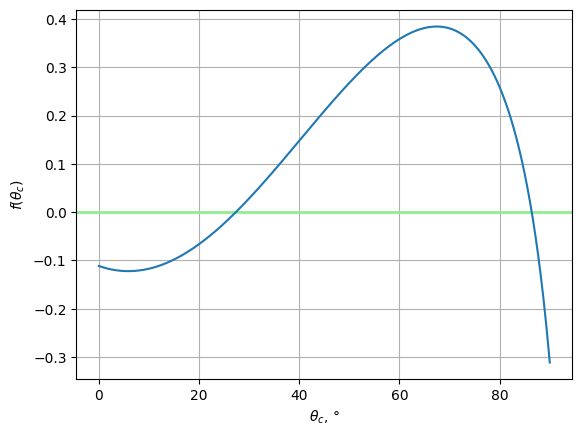

In [9]:
theta = np.linspace(1e-3, np.pi / 2, 500)

plt.axhline(0, color='lightgreen', linewidth=2)
plt.plot(np.degrees(theta), shock_equation(theta))
plt.xlabel(r'$\theta_c$, °')
plt.ylabel(r'$f(\theta_c)$')
plt.grid(True)
plt.show()

На интервале два корня: около $27^\circ$ и около $86^\circ$.
Больший корень соответствует неустойчивому стационарному решению (сильный скачок с большим приращением энтропии), поэтому его отбрасываем.

Для меньшего корня возьмём отрезок $[20^\circ, 40^\circ]$. Для проверки условий понадобятся производные, найдём их аналитически.
Обозначим $g(\theta) = \dfrac{\sin\theta}{\cos(\theta - \beta)}$, тогда
$$
g'(\theta) = \frac{\cos\theta\cos(\theta - \beta) + \sin\theta\sin(\theta - \beta)}{\cos^2(\theta - \beta)} = \frac{\cos\beta}{\cos^2(\theta - \beta)}, \quad
g''(\theta) = \frac{2\cos\beta\sin(\theta - \beta)}{\cos^3(\theta - \beta)}
$$
$$
f'(\theta) = \sin 2\theta - \frac{\kappa + 1}{2} \frac{\sin\beta\cos\beta}{\cos^2(\theta - \beta)}
$$
$$
f''(\theta) = 2\cos 2\theta - (\kappa + 1) \frac{\sin\beta\cos\beta\sin(\theta - \beta)}{\cos^3(\theta - \beta)}
$$

In [10]:
shock_derivative = lambda t: np.sin(2 * t) - k * np.sin(beta) * np.cos(beta) / np.cos(t - beta) ** 2
shock_second_derivative = lambda t: (
    2 * np.cos(2 * t) - 2 * k * np.sin(beta) * np.cos(beta) * np.sin(t - beta) / np.cos(t - beta) ** 3
)

theta_a, theta_b = math.radians(20), math.radians(40)

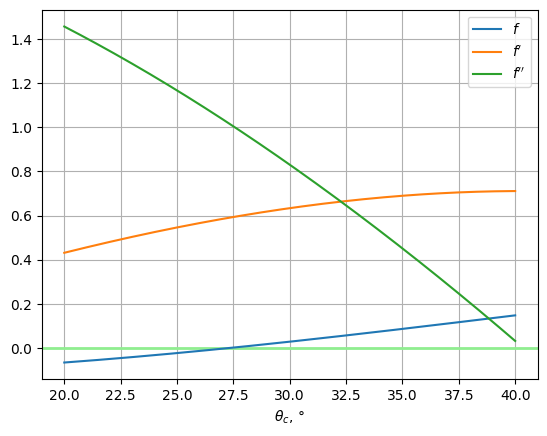

In [11]:
theta = np.linspace(theta_a, theta_b, 200)

plt.axhline(0, color='lightgreen', linewidth=2)
plt.plot(np.degrees(theta), shock_equation(theta), label=r"$f$")
plt.plot(np.degrees(theta), shock_derivative(theta), label=r"$f'$")
plt.plot(np.degrees(theta), shock_second_derivative(theta), label=r"$f''$")
plt.xlabel(r'$\theta_c$, °')
plt.legend()
plt.grid(True)
plt.show()

Проверим условия существования единственного корня и сходимости на отрезке

In [12]:
check_root_conditions(shock_equation, shock_derivative, shock_second_derivative, theta_a, theta_b)

{'f(a) f(b) < 0': True, "f' не меняет знак": True, "f'' не меняет знак": True}

Все условия выполняются, значит на $[20^\circ, 40^\circ]$ ровно один корень, и метод секущих с разгонными точками $x_0 = a$, $x_1 = b$ сходится.

In [13]:
theta_secant, iterations_secant = secant(shock_equation, theta_a, theta_b)

display(Math(fr"\theta_c = {sig(math.degrees(theta_secant))}^\circ"))
print(f"Итераций: {iterations_secant}")

<IPython.core.display.Math object>

Итераций: 5


## Параметры за КСУ
$$
u_1 = 1 - \frac{\sin(\theta_c - \beta)\cos\theta_c}{\sin\theta_c\cos(\theta_c - \beta)}, \quad
\rho_2 = \frac{\rho_1}{1 - u_1}, \quad
p_2 = p_1 + \rho_1 u_1 v_{1n}^2, \quad
T_2 = \frac{p_2}{\rho_2 R}
$$
Касательная составляющая скорости сохраняется: $v_{2\tau} = v_{1\tau} = v_1\cos\theta_c$.
Нормальная составляющая находится из уравнения неразрывности $\rho_1 v_{1n} = \rho_2 v_{2n}$, то есть $v_{2n} = v_{1n}(1 - u_1)$.
$$
v_2 = \sqrt{v_{2n}^2 + v_{2\tau}^2}, \quad a_2 = \sqrt{\kappa R T_2}, \quad M_2 = \frac{v_2}{a_2}
$$

In [14]:
def shock_parameters(theta_c):
    v1n = v1 * math.sin(theta_c)
    v1t = v1 * math.cos(theta_c)

    u1 = 1 - math.sin(theta_c - beta) * math.cos(theta_c) / (math.sin(theta_c) * math.cos(theta_c - beta))

    rho2 = rho1 / (1 - u1)
    p2 = p1 + rho1 * u1 * v1n ** 2
    T2 = p2 / (rho2 * R)

    v2n = v1n * (1 - u1)
    v2 = math.sqrt(v2n ** 2 + v1t ** 2)
    a2 = math.sqrt(kappa * R * T2)
    M2 = v2 / a2

    return {"p2": p2, "T2": T2, "rho2": rho2, "v2": v2, "a2": a2, "M2": M2}

params = shock_parameters(theta_secant)

In [15]:
results_1 = pd.DataFrame(
    {
        "Параметр": ["θc", "p2", "T2", "ρ2", "v2", "a2", "M2"],
        "Значение": [sig(math.degrees(theta_secant))] + [sig(params[key]) for key in ["p2", "T2", "rho2", "v2", "a2", "M2"]],
        "Размерность": ["°", "Па", "К", "кг/м³", "м/с", "м/с", "—"],
    }
)
results_1

,Параметр,Значение,Размерность
0,θc,27.4,°
1,p2,154000,Па
2,T2,358,К
3,ρ2,1.50,кг/м³
4,v2,950,м/с
5,a2,379,м/с
6,M2,2.51,—


In [16]:
regime = "сверхзвуковое" if params["M2"] > 1 else "дозвуковое"
print(f"M2 = {sig(params['M2'])} -> течение за КСУ {regime}")

M2 = 2.51 -> течение за КСУ сверхзвуковое


# Задание 2
Найдём корень уравнения методом Ньютона:
$$
f(x) = x^4 - 3x^3 + 5x - 10 = 0, \quad x \in [-5, 0]
$$
Аналитические производные:
$$
f'(x) = 4x^3 - 9x^2 + 5, \quad f''(x) = 12x^2 - 18x
$$

In [17]:
equation = lambda x: x ** 4 - 3 * x ** 3 + 5 * x - 10
derivative = lambda x: 4 * x ** 3 - 9 * x ** 2 + 5
second_derivative = lambda x: 12 * x ** 2 - 18 * x

a, b = -5, 0

Оценим начальное приближение графически

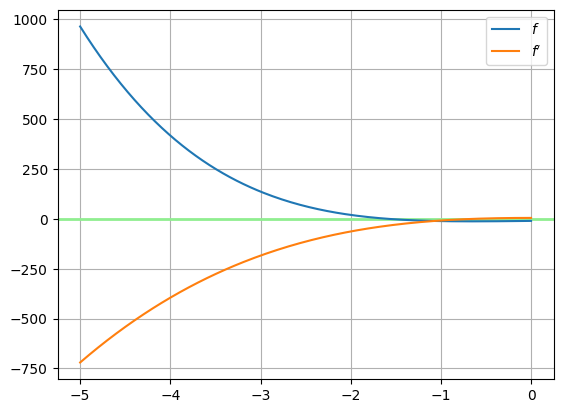

In [18]:
x = np.linspace(a, b, 200)

plt.axhline(0, color='lightgreen', linewidth=2)
plt.plot(x, equation(x), label=r"$f$")
plt.plot(x, derivative(x), label=r"$f'$")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
check_root_conditions(equation, derivative, second_derivative, a, b)

{'f(a) f(b) < 0': True,
 "f' не меняет знак": False,
 "f'' не меняет знак": False}

На всём отрезке $[-5, 0]$ производная $f'(x) = (x - 1)(4x^2 - 5x - 5)$ меняет знак в точке $x = \frac{5 - \sqrt{105}}{8} \approx -0.656$, поэтому отрезок нужно сузить.
По графику корень лежит между $-2$ и $-1$. Проверим отрезок $[-2, -1]$:

In [20]:
a, b = -2, -1

check_root_conditions(equation, derivative, second_derivative, a, b), check_newton_condition(equation, derivative, second_derivative, a, b)

({'f(a) f(b) < 0': True,
  "f' не меняет знак": True,
  "f'' не меняет знак": True},
 False)

Корень на $[-2, -1]$ единственный, но условие сходимости метода Ньютона нарушается у правой границы (при $x = -1$: $|f f''| = 330 > (f')^2 = 64$).
Сузим отрезок до $[-2, -1.5]$, так как $f(-1.5) < 0$:

In [21]:
a, b = -2, -1.5

check_root_conditions(equation, derivative, second_derivative, a, b), check_newton_condition(equation, derivative, second_derivative, a, b)

({'f(a) f(b) < 0': True,
  "f' не меняет знак": True,
  "f'' не меняет знак": True},
 True)

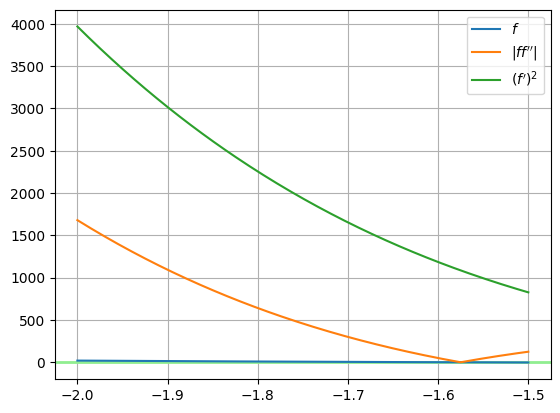

In [22]:
x = np.linspace(a, b, 200)

plt.axhline(0, color='lightgreen', linewidth=2)
plt.plot(x, equation(x), label=r"$f$")
plt.plot(x, np.abs(equation(x) * second_derivative(x)), label=r"$|f f''|$")
plt.plot(x, derivative(x) ** 2, label=r"$(f')^2$")
plt.legend()
plt.grid(True)
plt.show()

Все условия выполняются. Выберем начальное приближение из условия $f(x_0) f''(x_0) > 0$.

In [23]:
x0 = newton_start(equation, second_derivative, a, b)
x_newton, iterations = newton(equation, derivative, x0)

display(Math(fr"x_0 = {x0}, \quad x^* = {sig(x_newton)}"))
print(f"Итераций: {iterations}")

<IPython.core.display.Math object>

Итераций: 5


# Задание 3
Решим уравнение (4) с параметрами из задания 1 методом Ньютона на том же отрезке $[20^\circ, 40^\circ]$.
Следствие теоремы Больцано-Коши для него уже проверено, осталось проверить условие сходимости метода Ньютона.

In [24]:
check_newton_condition(shock_equation, shock_derivative, shock_second_derivative, theta_a, theta_b)

True

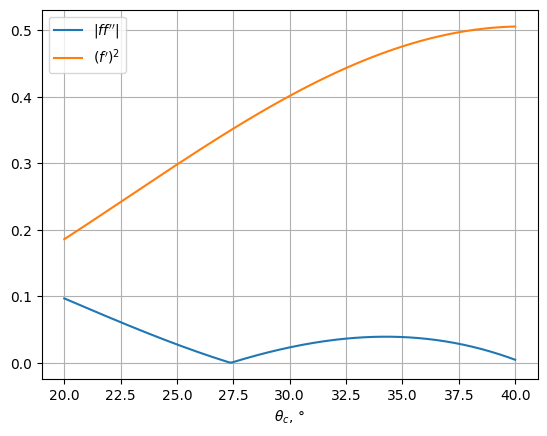

In [25]:
theta = np.linspace(theta_a, theta_b, 200)

plt.plot(np.degrees(theta), np.abs(shock_equation(theta) * shock_second_derivative(theta)), label=r"$|f f''|$")
plt.plot(np.degrees(theta), shock_derivative(theta) ** 2, label=r"$(f')^2$")
plt.xlabel(r'$\theta_c$, °')
plt.legend()
plt.grid(True)
plt.show()

In [26]:
theta0 = newton_start(shock_equation, shock_second_derivative, theta_a, theta_b)
theta_newton, iterations_newton = newton(shock_equation, shock_derivative, theta0)

display(Math(fr"\theta_0 = {sig(math.degrees(theta0))}^\circ, \quad \theta_c = {sig(math.degrees(theta_newton))}^\circ"))
print(f"Итераций: {iterations_newton}")

<IPython.core.display.Math object>

Итераций: 4


## Сравнение методов

In [27]:
time_secant = measure_time(secant, shock_equation, theta_a, theta_b)
time_newton = measure_time(newton, shock_equation, shock_derivative, theta0)

params_newton = shock_parameters(theta_newton)

comparison = pd.DataFrame(
    {
        "θc, °": [sig(math.degrees(theta_secant)), sig(math.degrees(theta_newton))],
        "p2, Па": [sig(params["p2"]), sig(params_newton["p2"])],
        "T2, К": [sig(params["T2"]), sig(params_newton["T2"])],
        "ρ2, кг/м³": [sig(params["rho2"]), sig(params_newton["rho2"])],
        "M2": [sig(params["M2"]), sig(params_newton["M2"])],
        "Итерации": [iterations_secant, iterations_newton],
        "Реальное время, мкс": [sig(time_secant), sig(time_newton)],
    },
    index=["Метод секущих", "Метод Ньютона"],
)
comparison

,"θc, °","p2, Па","T2, К","ρ2, кг/м³",M2,Итерации,"Реальное время, мкс"
Метод секущих,27.4,154000,358,1.50,2.51,5,6.23
Метод Ньютона,27.4,154000,358,1.50,2.51,4,6.08


In [28]:
display(Math(fr"|\theta_{{МС}} - \theta_{{МН}}| = {abs(math.degrees(theta_secant - theta_newton)):.2e}^\circ"))

<IPython.core.display.Math object>

# Валидация
Используем scipy для проверки корней

In [29]:
from scipy.optimize import brentq

theta_root = brentq(shock_equation, theta_a, theta_b)
root = brentq(equation, a, b)

In [30]:
np.allclose(theta_secant, theta_root, atol=eps), np.allclose(theta_newton, theta_root, atol=eps)

(True, True)

In [31]:
np.allclose(x_newton, root, atol=eps)

True

Проверим параметры за скачком по соотношениям для прямого скачка по нормальному числу Маха $M_{1n} = M_1 \sin\theta_c$:
$$
\frac{p_2}{p_1} = 1 + \frac{2\kappa}{\kappa + 1}(M_{1n}^2 - 1), \quad
\frac{\rho_2}{\rho_1} = \frac{(\kappa + 1) M_{1n}^2}{(\kappa - 1) M_{1n}^2 + 2}
$$

In [32]:
M1n = M1 * math.sin(theta_secant)
p2_check = p1 * (1 + 2 * kappa / (kappa + 1) * (M1n ** 2 - 1))
rho2_check = rho1 * (kappa + 1) * M1n ** 2 / ((kappa - 1) * M1n ** 2 + 2)

np.allclose([params["p2"], params["rho2"]], [p2_check, rho2_check])

True

# Выводы
1. Уравнение (4) на $(0, \pi/2)$ имеет два корня: $\approx 27.4^\circ$ и $\approx 86.4^\circ$. Больший корень отброшен как неустойчивое решение, угол наклона КСУ $\theta_c = 27.4^\circ$.
2. За КСУ: $p_2 = 154000$ Па, $T_2 = 358$ К, $\rho_2 = 1.50$ кг/м³, $M_2 = 2.51 > 1$, то есть течение за скачком остаётся **сверхзвуковым**. Параметры совпали с соотношениями для прямого скачка по нормальной составляющей числа Маха.
3. Корень уравнения $x^4 - 3x^3 + 5x - 10 = 0$ на $[-5, 0]$: $x^* = -1.58$. Исходный отрезок пришлось сузить до $[-2, -1.5]$, так как на $[-5, 0]$ производная меняет знак, а на $[-2, -1]$ не выполняется условие сходимости метода Ньютона.
4. Методы секущих и Ньютона дали одинаковый угол $\theta_c$ (разница порядка $10^{-10}$ градуса). Метод Ньютона сошёлся за меньшее число итераций (4 против 5), так как имеет второй порядок сходимости, а метод секущих — порядок $\approx 1.618$.
5. По реальному времени методы практически равны (единицы микросекунд): итерация метода Ньютона дороже из-за вычисления $f'$, но итераций меньше. Метод секущих не требует аналитической производной, что удобно при сложном виде $f$.